# 02 · Árbol de escenarios: nodos, historias y probabilidades

En este notebook se construye el árbol que representa todo lo que podría pasar en los tres trimestres de 2026. Se parte de una sola raíz, la decisión de diciembre de 2025, y en cada trimestre cada nodo se abre en ocho ramas, una por cada combinación posible de subidas y bajadas. Así se llega a 8 nodos en marzo, 64 en junio y 512 finales en septiembre: 585 en total. De cada nodo se registra su historia, es decir, las combinaciones observadas hasta ese momento, junto con su nodo padre, sus hijos y la probabilidad de llegar a él. El árbol se construye solo con los parámetros guardados en el notebook 01. Las fechas de 2026 aparecen únicamente como nombres de las etapas, no como datos.

In [2]:
import hashlib
import json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)

## 1. Carga de los parámetros guardados

Se verifica el hash de `calibration_parameters.json` antes de usarlo.

In [3]:
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PARAMS_DIR = ROOT / "results" / "parameters"
TREE_DIR = ROOT / "results" / "tree"
FIGURES_DIR = ROOT / "results" / "figures"
for d in [TREE_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def sha256_of(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

params_path = PARAMS_DIR / "calibration_parameters.json"
expected_hash = (PARAMS_DIR / "calibration_parameters.sha256").read_text().strip()
assert sha256_of(params_path) == expected_hash, "Los parámetros congelados cambiaron desde el notebook 01."
params = json.loads(params_path.read_text(encoding="utf-8"))

TICKERS = params["tickers"]
ACTIVE_STATES = params["active_states"]
S = len(ACTIVE_STATES)                   
Q_HAT = {u: params["states"][u]["q_hat"] for u in ACTIVE_STATES}
R_HAT = {u: np.array([params["states"][u]["R_hat"][t] for t in TICKERS]) for u in ACTIVE_STATES}

H = 4                                       
STAGES = {
    1: {"fecha": "Fin de dic-2025", "info": "Ninguna observación de 2026",       "decision": "Elegir x¹ (inversión inicial)"},
    2: {"fecha": "Fin de mar-2026", "info": "Se observa z₁",                      "decision": "Repartir la riqueza: x²"},
    3: {"fecha": "Fin de jun-2026", "info": "Se observan (z₁, z₂)",               "decision": "Repartir la riqueza: x³"},
    4: {"fecha": "Fin de sep-2026", "info": "Se observan (z₁, z₂, z₃)",           "decision": "Calcular exceso y déficit (y⁴, w⁴)"},
}

print(f"Parámetros verificados (hash {expected_hash[:12]}…).")
print(f"Estados activos: {S} -> {ACTIVE_STATES}")
if params["removed_states"]:
    print("Estados eliminados en calibración:", params["removed_states"])
assert np.isclose(sum(Q_HAT.values()), 1.0)

Parámetros verificados (hash 2d98f5cdf645…).
Estados activos: 8 -> ['AAA', 'AAB', 'ABA', 'ABB', 'BAA', 'BAB', 'BBA', 'BBB']


## 2. Construcción del árbol

**Indexación:** En cada etapa los nodos se numeran $k = 1, \dots, K_t$. Si $u$ es la terna en la posición $s \in \{0, \dots, S-1\}$ del orden fijo AAA, AAB, …, BBB, el hijo de $(t, k)$ por la rama $u$ es

$$\ell = S\,(k - 1) + s + 1, \qquad a(\ell) = \left\lfloor \frac{\ell - 1}{S} \right\rfloor + 1, \qquad C_{t+1}(k) = \{S(k-1)+1, \dots, Sk\}.$$

Con esta convención la historia determina el nodo sin ambigüedad, lo que se usará en el notebook 06 para pasar de las ternas observadas en 2026 al nodo correspondiente.

**Probabilidades:** $p^1_1 = 1$ y, para un hijo $\ell$ de $k$ por la rama $u$, $p^{t+1}_\ell = p^t_k\, \hat q_u$. Por la independencia temporal de la sección 2.5, $q_{\ell \mid k} = \hat q_u$ en todos los padres.

**Factores de rama:** Cada nodo con $t \ge 2$ guarda el vector $\hat R(u)$ de la rama que lo originó. Es el factor que convierte la inversión del padre en la riqueza del nodo, $V^t_\ell = \sum_i \hat R_i(u)\, x^{t-1}_{i, a(\ell)}$.

In [4]:
def child_index(k, u):
    return S * (k - 1) + ACTIVE_STATES.index(u) + 1

def parent_index(l):
    return (l - 1) // S + 1

def node_from_history(history):
    # Devuelve (t, k) del nodo cuya historia es la secuencia de ternas observadas.
    t, k = 1, 1
    for u in history:
        if u not in ACTIVE_STATES:
            raise KeyError(f"La terna {u} no tiene rama en el árbol.")
        t, k = t + 1, child_index(k, u)
    return t, k


rows = []
frontier = [{"k": 1, "history": (), "p": 1.0}]
node_id = 0
for t in range(1, H + 1):
    assert [n["k"] for n in frontier] == list(range(1, len(frontier) + 1))
    next_frontier = []
    for n in frontier:
        k, hist, p = n["k"], n["history"], n["p"]
        u = hist[-1] if hist else None
        row = {
            "node_id": node_id, "t": t, "k": k, "fecha": STAGES[t]["fecha"],
            "is_leaf": t == H,
            "history": "|".join(hist) if hist else "raíz",
            "z1": hist[0] if len(hist) > 0 else "", "z2": hist[1] if len(hist) > 1 else "",
            "z3": hist[2] if len(hist) > 2 else "",
            "branch_state": u or "",
            "parent_k": parent_index(k) if t > 1 else np.nan,
            "q_cond": Q_HAT[u] if u else np.nan,
            "p_cum": p,
            "first_child_k": S * (k - 1) + 1 if t < H else np.nan,
            "last_child_k": S * k if t < H else np.nan,
            "n_children": S if t < H else 0,
        }
        for i, tk in enumerate(TICKERS):
            row[f"R_branch_{tk}"] = R_HAT[u][i] if u else np.nan
        rows.append(row)
        node_id += 1
        if t < H:
            for v in ACTIVE_STATES:
                next_frontier.append({"k": child_index(k, v), "history": hist + (v,), "p": p * Q_HAT[v]})
    frontier = sorted(next_frontier, key=lambda n: n["k"])

tree = pd.DataFrame(rows)
for c in ["parent_k", "first_child_k", "last_child_k"]:
    tree[c] = tree[c].astype("Int64")

# node_id del padre, para facilitar la lectura del archivo exportado
first_id = tree.groupby("t")["node_id"].min().to_dict()
tree["parent_node_id"] = [
    pd.NA if t == 1 else first_id[t - 1] + int(pk) - 1 for t, pk in zip(tree["t"], tree["parent_k"])
]
tree["parent_node_id"] = tree["parent_node_id"].astype("Int64")

K = tree.groupby("t").size().to_dict()
print("Nodos por etapa K_t:", K, "· total:", len(tree))

Nodos por etapa K_t: {1: 1, 2: 8, 3: 64, 4: 512} · total: 585


## 3. Verificaciones

Se comprueban los tamaños, la indexación, las probabilidades por etapa, la suma de condicionales por padre, el cociente $q_{\ell\mid k} = p^{t+1}_\ell / p^t_k$, y que $p^4_k$ coincida con el producto $\hat q_{z_1}\hat q_{z_2}\hat q_{z_3}$ de su trayectoria.

In [5]:
checks = []
tol = 1e-12

assert K == {t: S ** (t - 1) for t in range(1, H + 1)}
assert len(tree) == sum(S ** (t - 1) for t in range(1, H + 1))
checks.append(f"K_t = {[K[t] for t in range(1, H + 1)]}, total {len(tree)} nodos "
              f"({sum(K[t] for t in range(1, H))} de decisión y {K[H]} hojas)")

assert tree.loc[tree["t"] == 1, "p_cum"].item() == 1.0
checks.append("p¹₁ = 1")

for t in range(1, H + 1):
    s = tree.loc[tree["t"] == t, "p_cum"].sum()
    assert abs(s - 1) < tol, f"Las probabilidades de la etapa {t} suman {s}."
leaf_sum = tree.loc[tree["is_leaf"], "p_cum"].sum()
checks.append(f"las probabilidades de cada etapa suman 1; hojas: Σ p⁴ = {leaf_sum:.15f}")

assert tree["history"].is_unique
checks.append("historias únicas: cada trayectoria tiene un solo nodo")

pk = tree.set_index(["t", "k"])["p_cum"]
max_ratio_err, max_sum_err = 0.0, 0.0
for t in range(1, H):
    for k in range(1, K[t] + 1):
        kids = tree[(tree["t"] == t + 1) & (tree["parent_k"] == k)]
        assert kids["k"].tolist() == list(range(S * (k - 1) + 1, S * k + 1))
        max_sum_err = max(max_sum_err, abs(kids["q_cond"].sum() - 1))
        ratio = kids["p_cum"].to_numpy() / pk[(t, k)]
        max_ratio_err = max(max_ratio_err, np.max(np.abs(ratio - kids["q_cond"].to_numpy())))
assert max_sum_err < tol and max_ratio_err < tol
checks.append(f"en los {sum(K[t] for t in range(1, H))} padres, Σ q(ℓ|k) = 1 "
              f"(error máx. {max_sum_err:.1e}) y p^(t+1)_ℓ / p^t_k = q̂_u (error máx. {max_ratio_err:.1e})")

leaves = tree[tree["is_leaf"]]
prod = np.array([Q_HAT[a] * Q_HAT[b] * Q_HAT[c] for a, b, c in zip(leaves["z1"], leaves["z2"], leaves["z3"])])
assert np.allclose(prod, leaves["p_cum"].to_numpy(), rtol=0, atol=tol)
checks.append("p⁴_k = q̂_z1 · q̂_z2 · q̂_z3 en las hojas")

for h in [("AAA",), (ACTIVE_STATES[-1], ACTIVE_STATES[0]), tuple(ACTIVE_STATES[2:5])]:
    t, k = node_from_history(h)
    assert tree.set_index(["t", "k"]).at[(t, k), "history"] == "|".join(h)
checks.append("node_from_history reproduce el nodo de cada historia")

for c in checks:
    print("  ✔", c)

  ✔ K_t = [1, 8, 64, 512], total 585 nodos (73 de decisión y 512 hojas)
  ✔ p¹₁ = 1
  ✔ las probabilidades de cada etapa suman 1; hojas: Σ p⁴ = 1.000000000000000
  ✔ historias únicas: cada trayectoria tiene un solo nodo
  ✔ en los 73 padres, Σ q(ℓ|k) = 1 (error máx. 0.0e+00) y p^(t+1)_ℓ / p^t_k = q̂_u (error máx. 0.0e+00)
  ✔ p⁴_k = q̂_z1 · q̂_z2 · q̂_z3 en las hojas
  ✔ node_from_history reproduce el nodo de cada historia


## 4. Esquema del árbol por niveles 

Cada nodo de decisión tiene $S = 8$ hijos, uno por terna. El esquema resume los cuatro niveles con su momento, la información disponible y la decisión que se toma.

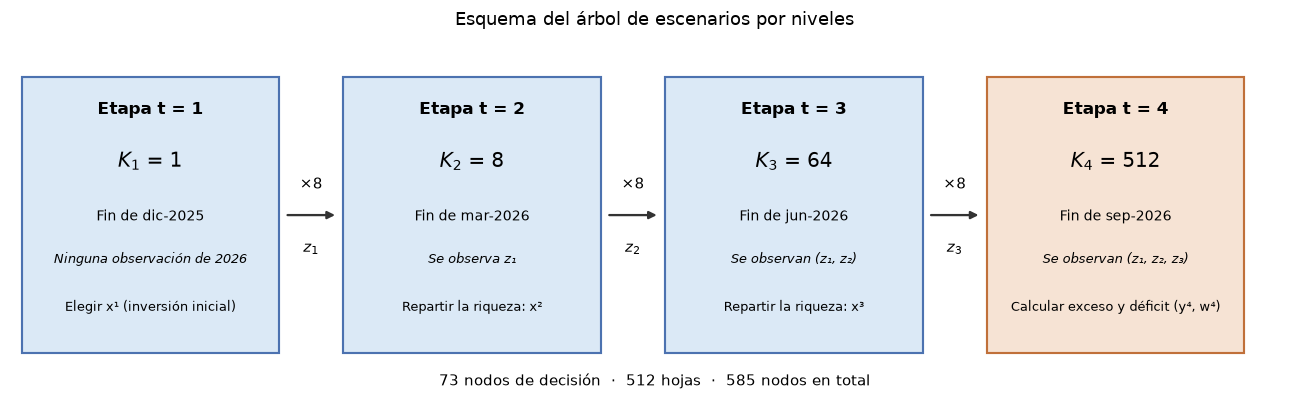

In [6]:
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.set_xlim(-0.5, 4 * 3 - 0.5); ax.set_ylim(-1.6, 1.8); ax.axis("off")
for t in range(1, H + 1):
    x = (t - 1) * 3 + 0.8
    color = "#dbe9f6" if t < H else "#f6e3d4"
    ax.add_patch(plt.Rectangle((x - 1.2, -1.2), 2.4, 2.6, fc=color, ec="#4c72b0" if t < H else "#c0703a", lw=1.4))
    ax.text(x, 1.05, f"Etapa t = {t}", ha="center", fontsize=11, weight="bold")
    ax.text(x, 0.55, f"$K_{t}$ = {K[t]}", ha="center", fontsize=13)
    ax.text(x, 0.05, STAGES[t]["fecha"], ha="center", fontsize=9)
    ax.text(x, -0.35, STAGES[t]["info"], ha="center", fontsize=8.5, style="italic")
    ax.text(x, -0.8, STAGES[t]["decision"], ha="center", fontsize=8.5)
    if t < H:
        ax.annotate("", xy=(x + 1.75, 0.1), xytext=(x + 1.25, 0.1),
                    arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#333"))
        ax.text(x + 1.5, 0.35, f"×{S}", ha="center", fontsize=10)
        ax.text(x + 1.5, -0.25, f"$z_{t}$", ha="center", fontsize=10)
ax.text(5.5, -1.5, f"{sum(K[t] for t in range(1, H))} nodos de decisión  ·  {K[H]} hojas  ·  "
        f"{len(tree)} nodos en total", ha="center", fontsize=9.5)
ax.set_title("Esquema del árbol de escenarios por niveles", fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_tree_levels.png")
plt.show()

## 5. Ramas de la raíz y de un nodo de etapa 2 

Para el detalle de etapa 2 se elige el nodo alcanzado por la terna de **mayor probabilidad** $\hat q_u$ (en caso de empate, la primera en el orden fijo). La elección se puede cambiar en `EXAMPLE_STAGE2_STATE`. Como los estados son independientes en el tiempo, las condicionales de sus hijos coinciden con las de la raíz; lo que cambia son las probabilidades acumuladas $p^3_\ell = p^2_k\,\hat q_u$.

In [7]:
EXAMPLE_STAGE2_STATE = max(ACTIVE_STATES, key=lambda u: (Q_HAT[u], -ACTIVE_STATES.index(u)))
_, K_EX = node_from_history((EXAMPLE_STAGE2_STATE,))

def branch_table(t_parent, k_parent):
    kids = tree[(tree["t"] == t_parent + 1) & (tree["parent_k"] == k_parent)]
    out = kids[["k", "history", "branch_state", "q_cond", "p_cum"] + [f"R_branch_{tk}" for tk in TICKERS]].copy()
    out.columns = ["ℓ", "historia", "rama u", "q(ℓ|k)", f"p^{t_parent + 1}_ℓ"] + [f"R̂_{tk}(u)" for tk in TICKERS]
    return out.set_index("ℓ")

print("Ramas de la raíz (t = 1, k = 1):")
with pd.option_context("display.float_format", "{:.6f}".format):
    display(branch_table(1, 1))
print(f"\nRamas del nodo de etapa 2 con historia {EXAMPLE_STAGE2_STATE} (t = 2, k = {K_EX}, "
      f"p²_k = {pk[(2, K_EX)]:.6f}):")
with pd.option_context("display.float_format", "{:.6f}".format):
    display(branch_table(2, K_EX))

Ramas de la raíz (t = 1, k = 1):


,historia,rama u,q(ℓ|k),p^2_ℓ,R̂_SPY(u),R̂_LQD(u),R̂_GLD(u)
ℓ,,,,,,,
1,AAA,AAA,0.484375,0.484375,1.070526,1.034144,1.065740
2,AAB,AAB,0.093750,0.093750,1.069237,1.020277,0.963796
3,ABA,ABA,0.046875,0.046875,1.085100,0.986717,1.068594
4,ABB,ABB,0.171875,0.171875,1.043089,0.977068,0.931211
5,BAA,BAA,0.046875,0.046875,0.901860,1.031670,1.129822
6,BAB,BAB,0.046875,0.046875,0.967833,1.014010,0.950266
7,BBA,BBA,0.062500,0.062500,0.903526,0.962917,1.046330
8,BBB,BBB,0.046875,0.046875,0.919115,0.935849,0.937469



Ramas del nodo de etapa 2 con historia AAA (t = 2, k = 1, p²_k = 0.484375):


,historia,rama u,q(ℓ|k),p^3_ℓ,R̂_SPY(u),R̂_LQD(u),R̂_GLD(u)
ℓ,,,,,,,
1,AAA|AAA,AAA,0.484375,0.234619,1.070526,1.034144,1.065740
2,AAA|AAB,AAB,0.093750,0.045410,1.069237,1.020277,0.963796
3,AAA|ABA,ABA,0.046875,0.022705,1.085100,0.986717,1.068594
4,AAA|ABB,ABB,0.171875,0.083252,1.043089,0.977068,0.931211
5,AAA|BAA,BAA,0.046875,0.022705,0.901860,1.031670,1.129822
6,AAA|BAB,BAB,0.046875,0.022705,0.967833,1.014010,0.950266
7,AAA|BBA,BBA,0.062500,0.030273,0.903526,0.962917,1.046330
8,AAA|BBB,BBB,0.046875,0.022705,0.919115,0.935849,0.937469


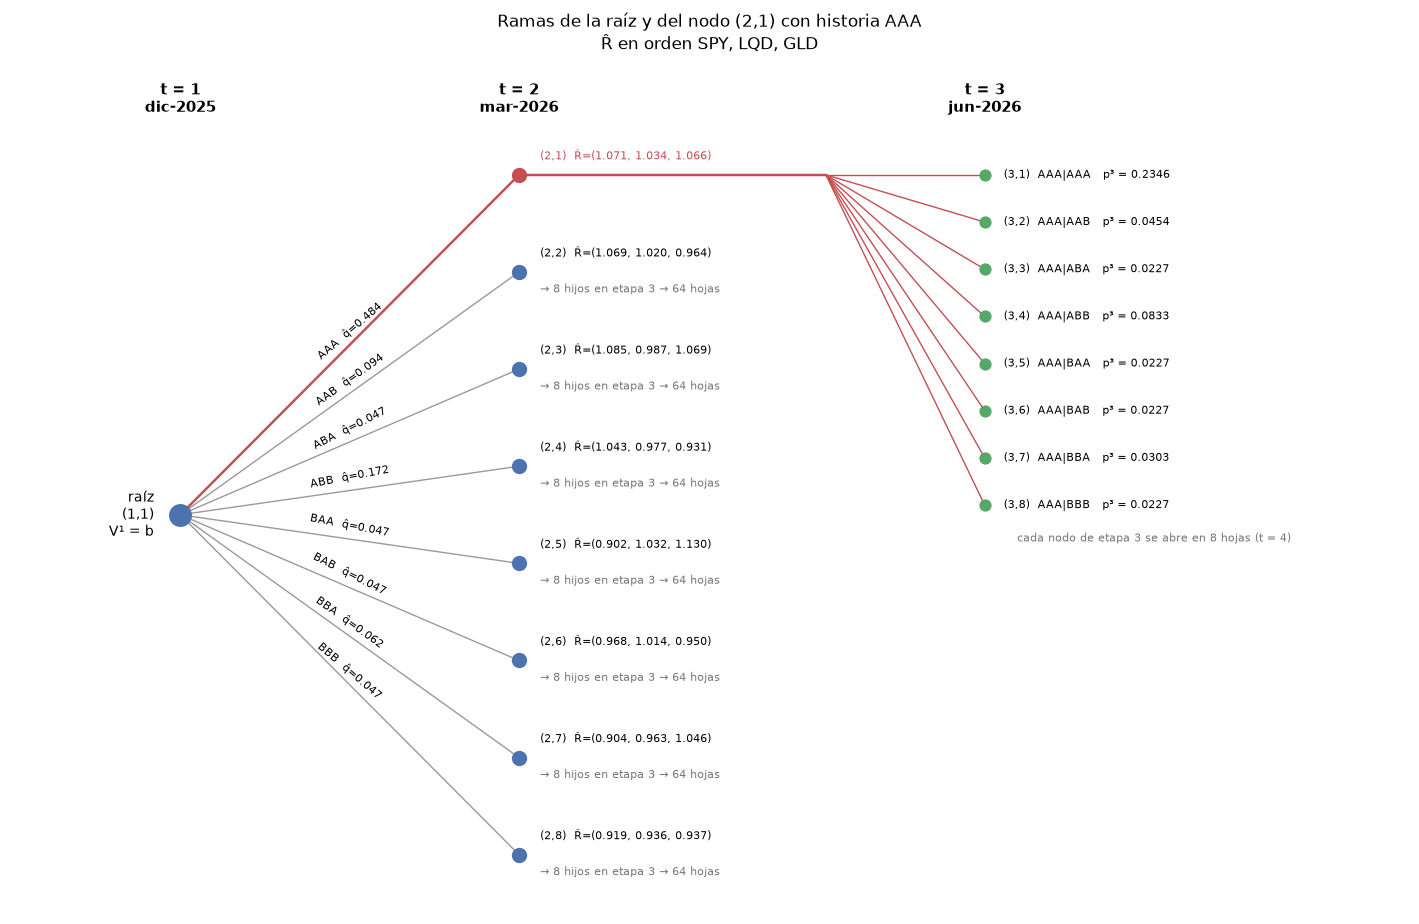

In [8]:
def fmt_R(u):
    return "(" + ", ".join(f"{v:.3f}" for v in R_HAT[u]) + ")"

fig, ax = plt.subplots(figsize=(13, 8.5))
ax.axis("off")
x1, x2, x3 = 0.0, 3.2, 7.6         
x_fan = x2 + 2.9                 
y_top, y_bot = 7.0, -7.0
y2 = np.linspace(y_top, y_bot, S)

ax.plot(x1, 0, "o", ms=14, color="#4c72b0", zorder=6)
ax.text(x1 - 0.25, 0, "raíz\n(1,1)\nV¹ = b", ha="right", va="center", fontsize=9)
for s, u in enumerate(ACTIVE_STATES):
    hl = u == EXAMPLE_STAGE2_STATE
    ax.plot([x1, x2], [0, y2[s]], color="#c44e52" if hl else "#999", lw=1.6 if hl else 0.9, zorder=2)
    ax.plot(x2, y2[s], "o", ms=9, color="#c44e52" if hl else "#4c72b0", zorder=6)
    ang = np.degrees(np.arctan2(y2[s], x2 - x1)) * 0.62
    ax.text((x1 + x2) / 2, y2[s] / 2 + 0.28, f"{u}  q̂={Q_HAT[u]:.3f}", fontsize=7.5,
            ha="center", va="center", rotation=ang, zorder=5)
    ax.text(x2 + 0.2, y2[s] + 0.32, f"(2,{child_index(1, u)})  R̂={fmt_R(u)}", fontsize=7.5,
            color="#c44e52" if hl else "black", zorder=5)
    if not hl:
        ax.text(x2 + 0.2, y2[s] - 0.42, f"→ {S} hijos en etapa 3 → {S * S} hojas", fontsize=7, color="#777")

sh = ACTIVE_STATES.index(EXAMPLE_STAGE2_STATE)
y_par = y2[sh]
half = 3.4
center = np.clip(y_par, y_bot + half, y_top - half)
y3 = np.linspace(center + half, center - half, S)
ax.plot([x2, x_fan], [y_par, y_par], color="#c44e52", lw=1.6, zorder=3)
for s, u in enumerate(ACTIVE_STATES):
    ax.plot([x_fan, x3], [y_par, y3[s]], color="#c44e52", lw=0.9, zorder=2)
    ax.plot(x3, y3[s], "o", ms=7, color="#55a868", zorder=6)
    ax.text(x3 + 0.18, y3[s], f"(3,{child_index(K_EX, u)})  {EXAMPLE_STAGE2_STATE}|{u}   "
            f"p³ = {pk[(2, K_EX)] * Q_HAT[u]:.4f}", fontsize=7.4, va="center")
ax.text(x3 + 1.6, y3[-1] - 0.75, f"cada nodo de etapa 3 se abre en {S} hojas (t = 4)",
        fontsize=7.5, color="#777", ha="center")

for x, lab in [(x1, "t = 1\ndic-2025"), (x2, "t = 2\nmar-2026"), (x3, "t = 3\njun-2026")]:
    ax.text(x, 8.3, lab, ha="center", fontsize=9.5, weight="bold")
ax.set_xlim(-1.6, 11.6); ax.set_ylim(-8.2, 9.4)
ax.set_title(f"Ramas de la raíz y del nodo (2,{K_EX}) con historia {EXAMPLE_STAGE2_STATE}\n"
             f"R̂ en orden SPY, LQD, GLD", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_tree_branches_detail.png")
plt.show()

## 6. Resumen de las 512 trayectorias

Las trayectorias no son equiprobables: su probabilidad depende de cuántas veces aparece cada terna. Se reportan la más y la menos probable y cuántas trayectorias distintas comparten cada valor de probabilidad.

In [9]:
lv = tree[tree["is_leaf"]]
summary = pd.DataFrame({
    "valor": [len(lv), lv["p_cum"].sum(), lv["p_cum"].max(), lv["p_cum"].min(),
              lv["p_cum"].round(15).nunique()],
}, index=["hojas", "Σ p⁴", "p⁴ máxima", "p⁴ mínima", "valores distintos de p⁴"])
display(summary)
print("Trayectoria más probable :", lv.loc[lv["p_cum"].idxmax(), "history"])
print("Trayectoria menos probable:", lv.loc[lv["p_cum"].idxmin(), "history"])

,valor
hojas,512.000000
Σ p⁴,1.000000
p⁴ máxima,0.113644
p⁴ mínima,0.000103
valores distintos de p⁴,35.000000


Trayectoria más probable : AAA|AAA|AAA
Trayectoria menos probable: ABA|ABA|ABA


## 7. Exportación

El árbol completo se guarda en un archivo CSV con una fila por nodo, del que leen los notebooks 03 a 06. Junto a él se guarda un archivo de metadata con la huella digital de los parámetros con que se construyó y la del propio CSV, para que cualquier cambio posterior se detecte. Las columnas del archivo son las siguientes:

| Columna | Significado |
|---|---|
| `node_id` | Número único del nodo, de 0 a 584, ordenado por etapa y luego por $k$ |
| `t`, `k` | Etapa y número del nodo dentro de la etapa |
| `history`, `z1`, `z2`, `z3` | Historia completa del nodo y combinación observada en cada trimestre |
| `branch_state` | Combinación de la rama por la que se llega al nodo |
| `parent_k`, `parent_node_id` | Nodo padre en la etapa anterior |
| `first_child_k`, `last_child_k`, `n_children` | Primer y último hijo, y cuántos hijos tiene |
| `q_cond`, `p_cum` | Probabilidad de llegar desde el padre y probabilidad total de llegar al nodo |
| `R_branch_SPY`, `R_branch_LQD`, `R_branch_GLD` | Factor de cada activo en la rama que llega al nodo |

In [10]:
cols = ["node_id", "t", "k", "fecha", "is_leaf", "history", "z1", "z2", "z3", "branch_state",
        "parent_k", "parent_node_id", "first_child_k", "last_child_k", "n_children", "q_cond", "p_cum"] + \
       [f"R_branch_{tk}" for tk in TICKERS]
tree_csv = TREE_DIR / "scenario_tree_nodes.csv"
tree[cols].to_csv(tree_csv, index=False, float_format="%.15g")

tree_meta = {
    "description": "Árbol de escenarios (Práctica 2, sección 3.2)",
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "calibration_parameters_sha256": expected_hash,
    "H": H, "S": S, "active_states": ACTIVE_STATES, "tickers": TICKERS,
    "K_t": {str(t): K[t] for t in range(1, H + 1)},
    "n_nodes": len(tree),
    "indexing": "hijo de (t,k) por la rama en la posición s: l = S*(k-1) + s + 1; padre: (l-1)//S + 1",
    "example_stage2_node": {"t": 2, "k": K_EX, "history": EXAMPLE_STAGE2_STATE},
    "sum_leaf_probabilities": float(leaf_sum),
    "checks_passed": checks,
    "csv_file": str(tree_csv.relative_to(ROOT)),
    "csv_sha256": sha256_of(tree_csv),
}
(TREE_DIR / "tree_metadata.json").write_text(json.dumps(tree_meta, indent=2, ensure_ascii=False),
                                              encoding="utf-8")
print("Guardado:")
for p in [tree_csv, TREE_DIR / "tree_metadata.json", FIGURES_DIR / "02_tree_levels.png",
          FIGURES_DIR / "02_tree_branches_detail.png"]:
    print("  ", p.relative_to(ROOT))
print(f"Σ p⁴ = {leaf_sum:.15f}")

Guardado:
   results/tree/scenario_tree_nodes.csv
   results/tree/tree_metadata.json
   results/figures/02_tree_levels.png
   results/figures/02_tree_branches_detail.png
Σ p⁴ = 1.000000000000000
